# Trabajo Práctico Integrador – Introducción al Análisis de Datos
## Entrega 5: Primer modelo de clasificación (Semana 12)

**Apellido y nombre:** Aguillón, Fernando  
**Comisión:** 5  
**Dataset:** E – reservas hoteleras  
**Recorrido:** SQL + R  
**Modelo:** Árbol de decisión

Este notebook retoma las decisiones de las Entregas 1 a 4 y la planificación de Semana 11. El objetivo es anticipar si una reserva será cancelada **al momento de registrarla**.

**Archivo esperado en Google Colab:** `/content/hotel booking TPI grupo E.csv`

Ejecutá todas las celdas en orden, revisá los resultados y completá las interpretaciones. Los resultados de evaluación se calculan con el CSV al ejecutar el notebook; no se inventan valores.

## 1. Objetivo y variables seleccionadas

La variable objetivo es `is_canceled`: `0` = no cancelada y `1` = cancelada. Es un problema de clasificación supervisada porque el modelo aprende con reservas cuyo estado conocemos y luego predice la categoría de otras reservas.

Se retoman las ocho variables predictoras de Semana 11:

| Variable | Justificación |
|---|---|
| `hotel` | En la Entrega 4, City Hotel tuvo 41,74 % de cancelaciones y Resort Hotel 27,75 %. |
| `lead_time` | Las canceladas presentaron una mediana de anticipación de 113 días, frente a 44 días en no canceladas. |
| `adr` | Se observaron diferencias moderadas entre grupos. Confirmar que el valor esté disponible al registrar la reserva. |
| `market_segment` | Describe el segmento de mercado. |
| `distribution_channel` | Identifica el canal por el que llegó la reserva. |
| `deposit_type` | Describe el tipo de depósito o garantía. |
| `customer_type` | Caracteriza el tipo de cliente. |
| `previous_cancellations` | Resume cancelaciones anteriores del cliente. |

Las variables categóricas se tratarán como factores de R. Los faltantes categóricos se identificarán como `Sin especificar`; los faltantes numéricos se completarán con la mediana calculada solo en entrenamiento.

## 2. Exclusiones para evitar identificadores y fuga de información

- `booking_id`: identificador, no característica predictiva.
- `is_canceled`: es la respuesta que queremos predecir, no puede ser predictora.
- `reservation_status` y `reservation_status_date`: describen el estado final o su fecha y podrían revelar el resultado.
- `assigned_room_type`: habitación finalmente asignada; podría conocerse después del registro.
- `booking_changes`: puede acumular modificaciones posteriores.
- `days_in_waiting_list`: puede depender de eventos posteriores.
- `company`: excluida en la Entrega 2 por su elevada proporción de faltantes.

**Consideración sobre ADR:** Se incluye `adr` como variable predictora bajo el supuesto de que su valor estaba disponible al momento de registrar la reserva. Por lo tanto, se considera válida para el objetivo de anticipar cancelaciones. Esta decisión deberá revisarse si se utiliza el modelo en un entorno real, verificando que el valor no haya sido actualizado posteriormente.

## 3. Librerías y entorno SQL

DuckDB permite realizar la selección de datos mediante SQL. R se utiliza para preparar los datos, separar entrenamiento y prueba y entrenar el árbol.

In [9]:
# Configurar identificación del entorno Linux
options(HTTPUserAgent = sprintf(
  "R/%s R (%s)",
  getRversion(),
  paste(
    getRversion(),
    R.version["platform"],
    R.version["arch"],
    R.version["os"]
  )
))

# Instalar DuckDB desde Posit
repositorio <- sprintf(
  "https://p3m.dev/cran/latest/bin/linux/manylinux_2_28-%s/%s",
  R.version$arch,
  paste(R.version$major, R.version$minor, sep = ".")
)

message("Instalando DuckDB desde Posit...")
install.packages("duckdb", repos = repositorio)

# Verificar
message("Verificando DuckDB...")

library(DBI)
library(duckdb)

print(packageVersion("duckdb"))

message("¡DuckDB está instalado y funcionando!")

Instalando DuckDB desde Posit...

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Verificando DuckDB...



[1] ‘2.0.0’


¡DuckDB está instalado y funcionando!



## 4. Carga del dataset original

Se carga el CSV original para que esta entrega sea reproducible e independiente de otros notebooks. Si el archivo no está en `/content/`, subilo a Colab antes de continuar.

In [10]:
ruta_csv <- "/content/hotel booking TPI grupo E.csv"
if (!file.exists(ruta_csv)) {
  stop("No se encontró el CSV. Subí 'hotel booking TPI grupo E.csv' a /content/ y volvé a ejecutar.")
}

datos_originales <- read.csv(
  ruta_csv, stringsAsFactors = FALSE,
  na.strings = c("", "NA"), check.names = FALSE
)
cat("Filas originales:", nrow(datos_originales), "\n")
cat("Columnas originales:", ncol(datos_originales), "\n")
stopifnot("is_canceled" %in% names(datos_originales))

Filas originales: 25000 
Columnas originales: 32 


## 5. Preparación inicial y continuidad de la Entrega 2

Se eliminan duplicados exactos, `booking_id` y `company`; los faltantes de `children` se reemplazan por cero; los faltantes de `agent` y `country` se identifican explícitamente; en `adr` se eliminan solo los valores negativos, conservando ceros y extremos. No se eliminan automáticamente las reservas sin huéspedes.

La imputación de las variables del modelo se hará después de separar entrenamiento y prueba.

In [11]:
df <- datos_originales
filas_iniciales <- nrow(df)
duplicados_exactos <- sum(duplicated(df))
faltantes_children <- if ("children" %in% names(df)) sum(is.na(df$children)) else NA_integer_
adr_negativos <- if ("adr" %in% names(df)) sum(!is.na(df$adr) & df$adr < 0) else NA_integer_

df <- df[!duplicated(df), , drop = FALSE]
df <- df[, !(names(df) %in% intersect(c("booking_id", "company"), names(df))), drop = FALSE]

if ("children" %in% names(df)) df$children[is.na(df$children)] <- 0
if ("agent" %in% names(df)) {
  df$agent <- as.character(df$agent)
  df$agent[is.na(df$agent) | trimws(df$agent) == ""] <- "Sin agente"
}
if ("country" %in% names(df)) {
  df$country <- as.character(df$country)
  df$country[is.na(df$country) | trimws(df$country) == ""] <- "Sin especificar"
}
if ("adr" %in% names(df)) {
  df$adr <- as.numeric(df$adr)
  df <- df[is.na(df$adr) | df$adr >= 0, , drop = FALSE]
}

cat("Duplicados exactos eliminados:", duplicados_exactos, "\n")
cat("Faltantes originales de children:", faltantes_children, "\n")
cat("ADR negativos detectados:", adr_negativos, "\n")
cat("Filas originales:", filas_iniciales, "\n")
cat("Filas después de la preparación:", nrow(df), "\n")

Duplicados exactos eliminados: 0 
Faltantes originales de children: 2 
ADR negativos detectados: 1 
Filas originales: 25000 
Filas después de la preparación: 24999 


## 6. Selección de variables mediante SQL

Se seleccionan la variable objetivo y las ocho predictoras. Si falta alguna columna, el notebook se detiene para revisar el nombre real en el CSV, en lugar de sustituirla silenciosamente.

In [12]:
variables_requeridas <- c(
  "is_canceled", "hotel", "lead_time", "adr", "market_segment",
  "distribution_channel", "deposit_type", "customer_type",
  "previous_cancellations"
)
variables_faltantes <- setdiff(variables_requeridas, names(df))
if (length(variables_faltantes) > 0) {
  stop(paste("No se encontraron estas columnas:",
             paste(variables_faltantes, collapse = ", ")))
}

df$is_canceled <- as.integer(as.character(df$is_canceled))
df$lead_time <- as.numeric(df$lead_time)
df$adr <- as.numeric(df$adr)
df$previous_cancellations <- as.numeric(df$previous_cancellations)

conexion <- DBI::dbConnect(duckdb::duckdb(), dbdir = ":memory:")
DBI::dbWriteTable(conexion, "reservas", df, overwrite = TRUE)

consulta_modelo <- "
SELECT is_canceled, hotel, lead_time, adr, market_segment,
       distribution_channel, deposit_type, customer_type,
       previous_cancellations
FROM reservas
WHERE is_canceled IN (0, 1)
"
datos_modelo <- DBI::dbGetQuery(conexion, consulta_modelo)

cat("Registros seleccionados por SQL:", nrow(datos_modelo), "\n")
cat("Columnas seleccionadas:", ncol(datos_modelo), "\n")
head(datos_modelo, 10)

duckdb keeps downloaded extensions and secrets in a temporary directory:
ℹ /tmp/RtmpPWGXyc/duckdb
This is removed when the R session ends.
• Extensions are re-downloaded each session.
• Secrets are lost.
ℹ Run duckdb(shared_home = TRUE) (or create ~/.duckdb) to keep them (suitable for most users).
ℹ Run duckdb(shared_home = FALSE) to accept the temporary directory (and silence this message).
ℹ See ?duckdb_storage for details and alternatives.


Registros seleccionados por SQL: 24999 
Columnas seleccionadas: 9 


,is_canceled,hotel,lead_time,adr,market_segment,distribution_channel,deposit_type,customer_type,previous_cancellations
,<int>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>
1,0,City Hotel,2,150.00,Direct,Direct,No Deposit,Transient,0
2,0,Resort Hotel,1,48.00,Online TA,TA/TO,No Deposit,Transient,0
3,1,City Hotel,28,190.00,Online TA,TA/TO,No Deposit,Transient,0
4,0,Resort Hotel,31,76.38,Online TA,TA/TO,No Deposit,Transient,0
5,0,Resort Hotel,204,153.57,Direct,Direct,No Deposit,Transient,0
6,1,Resort Hotel,172,125.90,Direct,Direct,No Deposit,Transient,0
7,1,City Hotel,272,62.80,Groups,TA/TO,No Deposit,Transient-Party,1
8,0,City Hotel,138,101.49,Online TA,TA/TO,No Deposit,Transient,0
9,0,City Hotel,56,195.00,Direct,Direct,No Deposit,Transient,0


## 7. Diagnóstico de faltantes y tipos

Se revisan los valores faltantes antes de tratarlos. Todavía no se calculan medianas: primero se separarán los datos en entrenamiento y prueba.

In [13]:
resumen_faltantes <- data.frame(
  variable = names(datos_modelo),
  tipo = sapply(datos_modelo, function(x) class(x)[1]),
  faltantes = sapply(datos_modelo, function(x) sum(is.na(x))),
  porcentaje_faltantes = round(
    100 * sapply(datos_modelo, function(x) mean(is.na(x))), 2
  )
)
resumen_faltantes

,variable,tipo,faltantes,porcentaje_faltantes
,<chr>,<chr>,<int>,<dbl>
is_canceled,is_canceled,integer,0,0
hotel,hotel,character,0,0
lead_time,lead_time,numeric,0,0
adr,adr,numeric,0,0
market_segment,market_segment,character,0,0
distribution_channel,distribution_channel,character,0,0
deposit_type,deposit_type,character,0,0
customer_type,customer_type,character,0,0
previous_cancellations,previous_cancellations,numeric,0,0


## 8. Distribución de la variable objetivo

Se comprueba cuántos registros pertenecen a cada clase. Si las categorías están desbalanceadas, la exactitud general podría resultar engañosa.

In [14]:
table(datos_modelo$is_canceled, useNA = "ifany")
frecuencia_clases <- as.data.frame(
  prop.table(table(datos_modelo$is_canceled)) * 100
)
names(frecuencia_clases) <- c("is_canceled", "porcentaje")
frecuencia_clases


    0     1 
15738  9261 

is_canceled,porcentaje
<fct>,<dbl>
0,62.95452
1,37.04548


## 9. Separación reproducible: entrenamiento y prueba

Se utiliza una división aproximada de 80 % para entrenamiento y 20 % para prueba, manteniendo la proporción de las clases mediante selección estratificada. La semilla `2026` permite reproducir la separación.

El conjunto de prueba queda reservado para evaluar el modelo. No se utilizará para calcular medianas ni parámetros de preparación.

In [15]:
datos_modelo <- datos_modelo[!is.na(datos_modelo$is_canceled), , drop = FALSE]
datos_modelo$is_canceled <- as.integer(datos_modelo$is_canceled)
if (!all(datos_modelo$is_canceled %in% c(0L, 1L))) {
  stop("is_canceled contiene valores distintos de 0 y 1.")
}

set.seed(2026)
indices_por_clase <- split(seq_len(nrow(datos_modelo)), datos_modelo$is_canceled)
indices_entrenamiento <- unlist(lapply(indices_por_clase, function(indices) {
  sample(indices, size = floor(0.80 * length(indices)))
}), use.names = FALSE)
indices_prueba <- setdiff(seq_len(nrow(datos_modelo)), indices_entrenamiento)

entrenamiento <- datos_modelo[indices_entrenamiento, , drop = FALSE]
prueba <- datos_modelo[indices_prueba, , drop = FALSE]

cat("Registros de entrenamiento:", nrow(entrenamiento), "\n")
cat("Registros de prueba:", nrow(prueba), "\n")
cat("\nProporción de clases en entrenamiento:\n")
print(prop.table(table(entrenamiento$is_canceled)))
cat("\nProporción de clases en prueba:\n")
print(prop.table(table(prueba$is_canceled)))

Registros de entrenamiento: 19998 
Registros de prueba: 5001 

Proporción de clases en entrenamiento:

       0        1 
0.629563 0.370437 

Proporción de clases en prueba:

        0         1 
0.6294741 0.3705259 


## 10. Tratamiento de faltantes sin fuga de información

Variables numéricas: `lead_time`, `adr` y `previous_cancellations`. Se reemplazan sus faltantes por la mediana calculada exclusivamente en entrenamiento y se aplica esa misma mediana al conjunto de prueba.

Variables categóricas: `hotel`, `market_segment`, `distribution_channel`, `deposit_type` y `customer_type`. Los faltantes se identifican como `Sin especificar`. Las categorías que aparezcan solo en prueba se codifican como `Otra categoría`.

In [16]:
variables_numericas <- c("lead_time", "adr", "previous_cancellations")
variables_categoricas <- c(
  "hotel", "market_segment", "distribution_channel",
  "deposit_type", "customer_type"
)

medianas_entrenamiento <- list()
for (variable in variables_numericas) {
  entrenamiento[[variable]] <- as.numeric(entrenamiento[[variable]])
  prueba[[variable]] <- as.numeric(prueba[[variable]])
  mediana_calculada <- median(entrenamiento[[variable]], na.rm = TRUE)
  if (!is.finite(mediana_calculada)) {
    stop(paste("No se pudo calcular una mediana válida para", variable))
  }
  medianas_entrenamiento[[variable]] <- mediana_calculada
  entrenamiento[[variable]][is.na(entrenamiento[[variable]])] <- mediana_calculada
  prueba[[variable]][is.na(prueba[[variable]])] <- mediana_calculada
}

normalizar_categoria <- function(x) {
  x <- trimws(as.character(x))
  x[is.na(x) | x == ""] <- "Sin especificar"
  x
}

niveles_entrenamiento <- list()
for (variable in variables_categoricas) {
  entrenamiento[[variable]] <- normalizar_categoria(entrenamiento[[variable]])
  prueba[[variable]] <- normalizar_categoria(prueba[[variable]])
  niveles <- unique(c(sort(unique(entrenamiento[[variable]])), "Otra categoría"))
  niveles_entrenamiento[[variable]] <- niveles
  valores_prueba <- prueba[[variable]]
  valores_prueba[!valores_prueba %in% niveles] <- "Otra categoría"
  entrenamiento[[variable]] <- factor(entrenamiento[[variable]], levels = niveles)
  prueba[[variable]] <- factor(valores_prueba, levels = niveles)
}

entrenamiento$is_canceled <- factor(
  ifelse(entrenamiento$is_canceled == 1, "Cancelada", "No cancelada"),
  levels = c("No cancelada", "Cancelada")
)
prueba$is_canceled <- factor(
  ifelse(prueba$is_canceled == 1, "Cancelada", "No cancelada"),
  levels = c("No cancelada", "Cancelada")
)

cat("Medianas calculadas solo con entrenamiento:\n")
print(unlist(medianas_entrenamiento))
cat("\nFaltantes en entrenamiento después del tratamiento:\n")
print(colSums(is.na(entrenamiento)))
cat("\nFaltantes en prueba después del tratamiento:\n")
print(colSums(is.na(prueba)))

Medianas calculadas solo con entrenamiento:
             lead_time                    adr previous_cancellations 
                  69.0                   94.5                    0.0 

Faltantes en entrenamiento después del tratamiento:
           is_canceled                  hotel              lead_time 
                     0                      0                      0 
                   adr         market_segment   distribution_channel 
                     0                      0                      0 
          deposit_type          customer_type previous_cancellations 
                     0                      0                      0 

Faltantes en prueba después del tratamiento:
           is_canceled                  hotel              lead_time 
                     0                      0                      0 
                   adr         market_segment   distribution_channel 
                     0                      0                      0 
          deposit

## 11. Entrenamiento del árbol de decisión

Se construye un árbol de decisión con `rpart` y el método `class`, porque la variable objetivo contiene dos categorías. Se limita inicialmente la profundidad a cinco niveles para mantener un árbol más sencillo de inspeccionar. Es un primer modelo, no una configuración optimizada.

In [19]:
# Comprobar si rpart está instalado
if (!requireNamespace("rpart", quietly = TRUE)) {
  message("Instalando rpart...")
  install.packages("rpart")
}

# Cargar el paquete
library(rpart)

# Comprobar que está disponible
packageVersion("rpart")

message("¡rpart está listo!")

[1] ‘4.1.27’

¡rpart está listo!



In [20]:
set.seed(2026)
modelo_arbol <- rpart(
  is_canceled ~ .,
  data = entrenamiento,
  method = "class",
  control = rpart.control(cp = 0.01, maxdepth = 5, minsplit = 20)
)
print(modelo_arbol)

n= 19998 

node), split, n, loss, yval, (yprob)
      * denotes terminal node

 1) root 19998 7408 No cancelada (0.629562956 0.370437044)  
   2) deposit_type=No Deposit,Refundable 17484 4911 No cancelada (0.719114619 0.280885381)  
     4) lead_time< 11.5 4072  445 No cancelada (0.890717092 0.109282908) *
     5) lead_time>=11.5 13412 4466 No cancelada (0.667014614 0.332985386)  
      10) previous_cancellations< 0.5 13036 4118 No cancelada (0.684105554 0.315894446) *
      11) previous_cancellations>=0.5 376   28 Cancelada (0.074468085 0.925531915) *
   3) deposit_type=Non Refund 2514   17 Cancelada (0.006762132 0.993237868) *


### Visualización del árbol
Cada división representa una condición sobre una variable; las hojas muestran la clase asignada por el árbol.

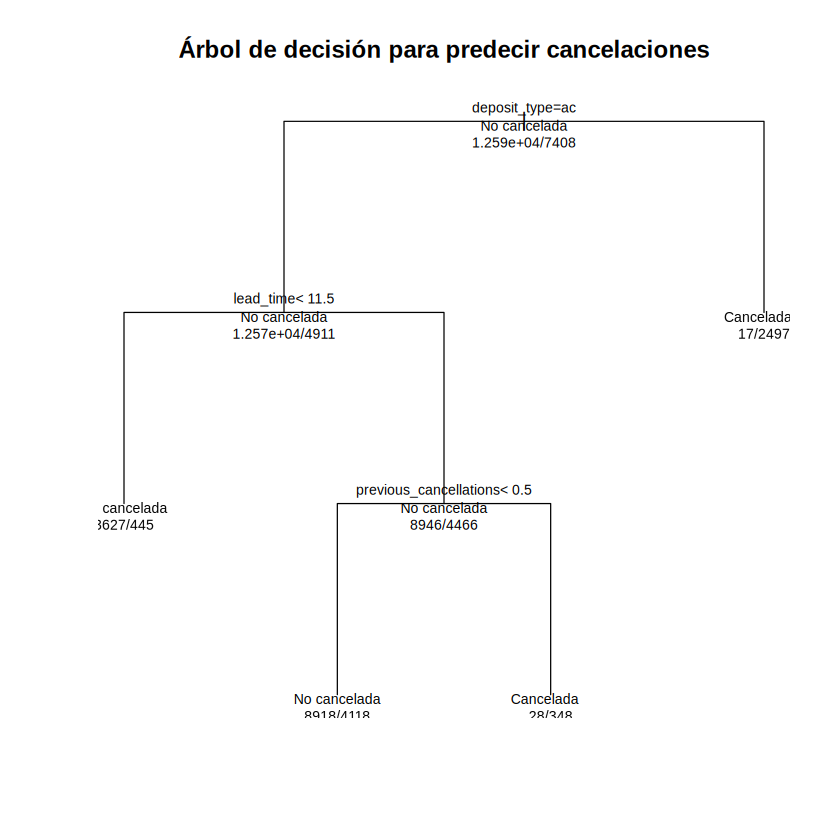

In [21]:
plot(modelo_arbol, uniform = TRUE,
     main = "Árbol de decisión para predecir cancelaciones")
text(modelo_arbol, use.n = TRUE, all = TRUE, cex = 0.7)

## 12. Predicciones sobre el conjunto de prueba

El modelo se aplica a los registros reservados para prueba. Se comparan los estados predichos con los estados reales. La probabilidad estimada es una salida del modelo, no una certeza sobre el futuro.

In [22]:
predicciones_clase <- predict(modelo_arbol, newdata = prueba, type = "class")
predicciones_probabilidad <- predict(modelo_arbol, newdata = prueba, type = "prob")

resultados_prueba <- data.frame(
  estado_real = prueba$is_canceled,
  estado_predicho = predicciones_clase,
  probabilidad_cancelacion = round(
    predicciones_probabilidad[, "Cancelada"], 4
  )
)
head(resultados_prueba, 20)

,estado_real,estado_predicho,probabilidad_cancelacion
,<fct>,<fct>,<dbl>
1,No cancelada,No cancelada,0.1093
7,Cancelada,Cancelada,0.9255
18,Cancelada,Cancelada,0.9932
25,Cancelada,No cancelada,0.3159
26,Cancelada,No cancelada,0.3159
28,No cancelada,No cancelada,0.3159
33,Cancelada,No cancelada,0.3159
34,Cancelada,No cancelada,0.3159
40,No cancelada,No cancelada,0.1093


## 13. Evaluación inicial: matriz de confusión y métricas

- **Verdadero negativo:** no cancelada correctamente identificada.
- **Verdadero positivo:** cancelada correctamente identificada.
- **Falso positivo:** se predijo cancelación, pero no ocurrió.
- **Falso negativo:** se predijo que no se cancelaría, pero sí ocurrió.

Se calculan exactitud, sensibilidad, especificidad y precisión para la clase Cancelada.

In [23]:
matriz_confusion <- table(
  Real = prueba$is_canceled,
  Predicho = predicciones_clase
)
matriz_confusion

vn <- matriz_confusion["No cancelada", "No cancelada"]
fp <- matriz_confusion["No cancelada", "Cancelada"]
fn <- matriz_confusion["Cancelada", "No cancelada"]
vp <- matriz_confusion["Cancelada", "Cancelada"]

exactitud <- sum(diag(matriz_confusion)) / sum(matriz_confusion)
sensibilidad <- if ((vp + fn) > 0) vp / (vp + fn) else NA_real_
especificidad <- if ((vn + fp) > 0) vn / (vn + fp) else NA_real_
precision_cancelacion <- if ((vp + fp) > 0) vp / (vp + fp) else NA_real_

metricas <- data.frame(
  metrica = c("Exactitud", "Sensibilidad", "Especificidad",
              "Precisión de cancelación"),
  valor = round(c(exactitud, sensibilidad, especificidad,
                  precision_cancelacion), 4)
)
metricas

              Predicho
Real           No cancelada Cancelada
  No cancelada         3139         9
  Cancelada            1155       698

metrica,valor
<chr>,<dbl>
Exactitud,0.7672
Sensibilidad,0.3767
Especificidad,0.9971
Precisión de cancelación,0.9873


## 14. Interpretación de las primeras predicciones

**1. Primeras predicciones:** De las primeras 20 reservas, el modelo clasificó correctamente 13 y se equivocó en 7. Por ejemplo, en la observación 25, el estado real era cancelada, pero el modelo predijo no cancelada.

**2. Utilidad posible:** El modelo podría ayudar al hotel a identificar reservas con mayor probabilidad de cancelación y priorizar su seguimiento, además de contribuir a planificar la disponibilidad de habitaciones.

**3. Errores:** Los falsos positivos pueden llevar al hotel a tomar precauciones innecesarias ante reservas que finalmente no se cancelan. Los falsos negativos son especialmente importantes porque representan reservas que el modelo considera seguras, pero que finalmente se cancelan.

## 15. Conclusión

En esta entrega se desarrolló un modelo de clasificación supervisada mediante un árbol de decisión para anticipar cancelaciones de reservas hoteleras. Se utilizaron ocho variables predictoras seleccionadas mediante SQL y se dividieron los datos en conjuntos de entrenamiento y prueba.

El modelo obtuvo una exactitud del 76,72 %, una especificidad del 99,71 % y una precisión de cancelación del 98,73 %. Sin embargo, su sensibilidad fue del 37,67 %, lo que demuestra que no logra identificar una proporción importante de las cancelaciones reales.

En la matriz de confusión se observaron 1.155 falsos negativos y solamente 9 falsos positivos. Por lo tanto, considero que el modelo puede ser útil como herramienta de apoyo para reconocer determinados patrones de cancelación, pero todavía presenta limitaciones importantes para anticiparlas. Sería necesario mejorar y comparar el modelo con otras alternativas antes de considerar su aplicación en un hotel real.